In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn torch shap

**Aim and tools**

This project compares biased matrix factorisation with a neural
collaborative-filtering model adapted for explicit movie-rating prediction.

MovieLens 100K was chosen because it provides real user–movie ratings,
supports both models on the same task, and is manageable within the
available computing resources.

Pandas and NumPy support data preparation and analysis. PyTorch provides
trainable factor tables, neural layers, automatic differentiation, and
optimisation. Using the same framework reduces implementation differences
between models; matrix factorisation remains a classical model because
its interaction function is a dot product without deep hidden layers.

Scikit-learn provides validation splits and evaluation metrics.
Matplotlib displays distributions, learning curves, and subgroup results.
SHAP provides model-agnostic local explanations.

The comparison considers rating accuracy, ranking quality, subgroup
errors, explainability, and measured training cost.

In [ ]:
import random
import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


In [ ]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

with urlopen(url, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as archive:
    with archive.open("ml-100k/u.data") as ratings_file:
        ratings = pd.read_csv(
            ratings_file,
            sep="\t",
            names=["user_id", "movie_id", "rating", "timestamp"]
        )

print(f"Ratings: {len(ratings):,}")
print(f"Users: {ratings['user_id'].nunique():,}")
print(f"Movies: {ratings['movie_id'].nunique():,}")

display(ratings.head())

Ratings: 100,000
Users: 943
Movies: 1,682


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [ ]:
user_counts = ratings.groupby("user_id").size()
movie_counts = ratings.groupby("movie_id").size()

possible_ratings = len(user_counts) * len(movie_counts)
sparsity = 1 - len(ratings) / possible_ratings

checks = pd.Series({
    "Missing values": ratings.isna().sum().sum(),
    "Duplicate user–movie pairs": ratings.duplicated(
        ["user_id", "movie_id"]
    ).sum(),
    "Ratings outside 1–5": (~ratings["rating"].between(1, 5)).sum()
})

display(checks.to_frame("Count"))

print(f"Unrated user–movie combinations: {sparsity:.2%}")
print(f"Average rating: {ratings['rating'].mean():.2f}")

display(
    pd.DataFrame({
        "Ratings per user": user_counts.describe(),
        "Ratings per movie": movie_counts.describe()
    }).round(2)
)

,Count
Missing values,0
Duplicate user–movie pairs,0
Ratings outside 1–5,0


Unrated user–movie combinations: 93.70%
Average rating: 3.53


,Ratings per user,Ratings per movie
count,943.00,1682.00
mean,106.04,59.45
std,100.93,80.38
min,20.00,1.00
25%,33.00,6.00
50%,65.00,27.00
75%,148.00,80.00
max,737.00,583.00


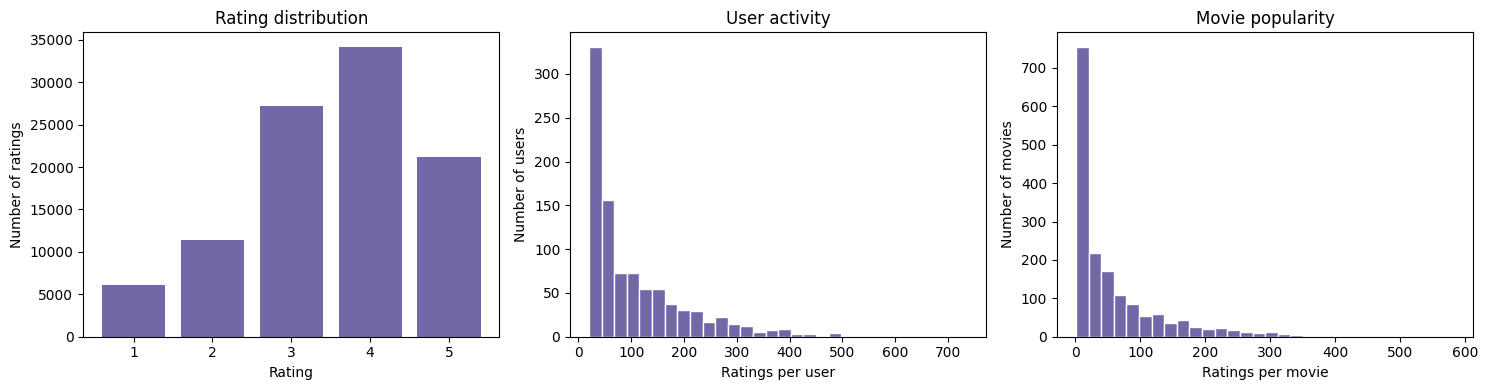

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rating_counts = ratings["rating"].value_counts().sort_index()

axes[0].bar(rating_counts.index, rating_counts.values, color="#7367A8")
axes[0].set(
    title="Rating distribution",
    xlabel="Rating",
    ylabel="Number of ratings",
    xticks=[1, 2, 3, 4, 5]
)

axes[1].hist(user_counts, bins=30, color="#7367A8", edgecolor="white")
axes[1].set(
    title="User activity",
    xlabel="Ratings per user",
    ylabel="Number of users"
)

axes[2].hist(movie_counts, bins=30, color="#7367A8", edgecolor="white")
axes[2].set(
    title="Movie popularity",
    xlabel="Ratings per movie",
    ylabel="Number of movies"
)

fig.tight_layout()
plt.show()

**Exploratory analysis**

Ratings are concentrated towards the higher end of the scale, with 4
being the most frequent score. User activity and movie popularity are
both right-skewed: many users and movies have relatively few ratings,
while a small number account for much greater activity.

These differences may affect recommendation quality because the models
have less evidence for less-active users and rarely rated movies.
Subgroup evaluation will examine whether prediction errors differ
across these groups. Unrated movies are treated as unknown preferences,
rather than negative feedback.

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split

ratings = ratings.reset_index(drop=True)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

folds = []

for fold, (dev_idx, test_idx) in enumerate(
    cv.split(ratings, ratings["user_id"]),
    start=1
):
    train_idx, val_idx = train_test_split(
        dev_idx,
        test_size=0.2,
        stratify=ratings.iloc[dev_idx]["user_id"],
        random_state=SEED + fold
    )

    folds.append({
        "train": train_idx,
        "val": val_idx,
        "test": test_idx
    })

In [ ]:
split_summary = []

for fold, split in enumerate(folds, start=1):
    train_idx = split["train"]
    val_idx = split["val"]
    test_idx = split["test"]

    assert not np.intersect1d(train_idx, val_idx).size
    assert not np.intersect1d(train_idx, test_idx).size
    assert not np.intersect1d(val_idx, test_idx).size
    assert len(train_idx) + len(val_idx) + len(test_idx) == len(ratings)

    train = ratings.iloc[train_idx]
    val = ratings.iloc[val_idx]
    test = ratings.iloc[test_idx]

    known_users = set(train["user_id"])
    known_movies = set(train["movie_id"])

    assert set(val["user_id"]).issubset(known_users)
    assert set(test["user_id"]).issubset(known_users)

    split_summary.append({
        "Fold": fold,
        "Training ratings": len(train),
        "Validation ratings": len(val),
        "Test ratings": len(test),
        "Validation ratings for unseen movies":
            (~val["movie_id"].isin(known_movies)).sum(),
        "Test ratings for unseen movies":
            (~test["movie_id"].isin(known_movies)).sum()
    })

test_indices = np.concatenate([split["test"] for split in folds])
assert np.array_equal(np.sort(test_indices), np.arange(len(ratings)))

display(pd.DataFrame(split_summary).set_index("Fold"))

,Training ratings,Validation ratings,Test ratings,Validation ratings for unseen movies,Test ratings for unseen movies
Fold,,,,,
1,64000,16000,20000,46,58
2,64000,16000,20000,33,50
3,64000,16000,20000,28,43
4,64000,16000,20000,38,51
5,64000,16000,20000,42,34


**Validation strategy**

Five-fold cross-validation is used to compare both models on identical
partitions. Ratings are stratified by user, keeping each user represented
in training. Within each fold, 20% of the remaining development ratings
are reserved for validation. Test ratings are excluded from model
training, hyperparameter selection, and early stopping.

This evaluates predictions for held-out ratings from existing users.
It does not directly evaluate new-user recommendations or future
performance, because the splits are random rather than chronological.

Movies absent from a fold's training subset are recorded separately.
A fallback based only on training data will handle these cases.
Rating-derived statistics and subgroup definitions will also be
calculated from each fold's training subset.

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rating_metrics(actual, predicted):
    return {
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted)
    }

In [ ]:
baseline_scores = []

for fold, split in enumerate(folds, start=1):
    train = ratings.iloc[split["train"]]
    val = ratings.iloc[split["val"]]

    global_mean = train["rating"].mean()
    user_means = train.groupby("user_id")["rating"].mean()

    predictions = {
        "Global mean": np.full(len(val), global_mean),
        "User mean": (
            val["user_id"]
            .map(user_means)
            .fillna(global_mean)
            .to_numpy()
        )
    }

    for name, predicted in predictions.items():
        baseline_scores.append({
            "Fold": fold,
            "Baseline": name,
            **rating_metrics(val["rating"], predicted)
        })

baseline_scores = pd.DataFrame(baseline_scores)

display(baseline_scores.round(4))

display(
    baseline_scores.groupby("Baseline")[["RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)

,Fold,Baseline,RMSE,MAE
0,1,Global mean,1.1266,0.9460
1,1,User mean,1.0432,0.8359
2,2,Global mean,1.1202,0.9398
3,2,User mean,1.0367,0.8310
4,3,Global mean,1.1268,0.9463
5,3,User mean,1.0379,0.8344
6,4,Global mean,1.1324,0.9497
7,4,User mean,1.0510,0.8429
8,5,Global mean,1.1221,0.9431
9,5,User mean,1.0427,0.8351


RMSE             MAE        
               mean     std    mean     std
Baseline                                   
Global mean  1.1256  0.0048  0.9450  0.0037
User mean    1.0423  0.0056  0.8359  0.0044

**Baseline predictions**

Two simple baselines provide reference points for rating prediction.
The global-mean baseline assigns every interaction the average training
rating. The user-mean baseline uses each user's average training rating,
falling back to the global mean when the user is unknown.

Both baselines are computed separately within each fold using training
ratings only. Validation RMSE and MAE indicate whether more complex
models improve on these simple predictions.

In [ ]:
from copy import deepcopy
from time import perf_counter
from torch import nn

class MatrixFactorisation(nn.Module):
    def __init__(self, n_users, n_movies, mean, factors=20):
        super().__init__()
        self.mean = float(mean)
        self.user_factors = nn.Embedding(n_users, factors)
        self.movie_factors = nn.Embedding(n_movies, factors)
        self.user_bias = nn.Embedding(n_users, 1)
        self.movie_bias = nn.Embedding(n_movies, 1)

        nn.init.normal_(self.user_factors.weight, std=0.05)
        nn.init.normal_(self.movie_factors.weight, std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, users, movies):
        interaction = (
            self.user_factors(users) * self.movie_factors(movies)
        ).sum(dim=1)

        return (
            self.mean
            + self.user_bias(users).squeeze(-1)
            + self.movie_bias(movies).squeeze(-1)
            + interaction
        )

In [ ]:
def predict_ratings(fitted, frame):
    model = fitted["model"]
    model_device = next(model.parameters()).device

    users = fitted["users"].get_indexer(frame["user_id"])
    movies = fitted["movies"].get_indexer(frame["movie_id"])
    known = (users >= 0) & (movies >= 0)

    predicted = (
        frame["user_id"]
        .map(fitted["user_means"])
        .fillna(fitted["mean"])
        .to_numpy(dtype=np.float64)
    )

    model.eval()
    with torch.no_grad():
        user_idx = torch.as_tensor(
            users[known], dtype=torch.long, device=model_device
        )
        movie_idx = torch.as_tensor(
            movies[known], dtype=torch.long, device=model_device
        )
        predicted[known] = model(user_idx, movie_idx).cpu().numpy()

    return np.clip(predicted, 1, 5)

In [ ]:
def fit_recommender(
    model_class, train, val, factors=20, lr=0.01,
    weight_decay=0.0001, batch_size=2048,
    max_epochs=40, patience=5, seed=SEED
):
    torch.manual_seed(seed)

    users = pd.Index(sorted(train["user_id"].unique()))
    movies = pd.Index(sorted(train["movie_id"].unique()))
    mean = train["rating"].mean()

    model = model_class(
        len(users), len(movies), mean, factors=factors
    ).to(device)

    fitted = {
        "model": model,
        "users": users,
        "movies": movies,
        "mean": mean,
        "user_means": train.groupby("user_id")["rating"].mean()
    }

    user_idx = torch.as_tensor(
        users.get_indexer(train["user_id"]),
        dtype=torch.long, device=device
    )
    movie_idx = torch.as_tensor(
        movies.get_indexer(train["movie_id"]),
        dtype=torch.long, device=device
    )
    targets = torch.as_tensor(
        train["rating"].to_numpy(),
        dtype=torch.float32, device=device
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr, weight_decay=weight_decay
    )
    loss_fn = nn.MSELoss()

    best_rmse = float("inf")
    best_state = None
    stale_epochs = 0
    history = []
    started = perf_counter()

    for epoch in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(len(train), device=device)

        for batch in order.split(batch_size):
            optimizer.zero_grad()
            predicted = model(user_idx[batch], movie_idx[batch])
            loss = loss_fn(predicted, targets[batch])
            loss.backward()
            optimizer.step()

        train_rmse = rating_metrics(
            train["rating"], predict_ratings(fitted, train)
        )["RMSE"]
        val_rmse = rating_metrics(
            val["rating"], predict_ratings(fitted, val)
        )["RMSE"]

        if not np.isfinite(val_rmse):
            raise ValueError("Validation RMSE is not finite")

        history.append({
            "Epoch": epoch,
            "Training RMSE": train_rmse,
            "Validation RMSE": val_rmse
        })

        if val_rmse < best_rmse:
            best_rmse = val_rmse
            best_state = deepcopy(model.state_dict())
            fitted["best_epoch"] = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"Epoch {epoch:2d} | "
                f"train RMSE {train_rmse:.4f} | "
                f"val RMSE {val_rmse:.4f}"
            )

        if stale_epochs >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    fitted["history"] = pd.DataFrame(history)
    fitted["training_seconds"] = perf_counter() - started
    return fitted

Epoch  1 | train RMSE 1.0155 | val RMSE 1.0341
Epoch  5 | train RMSE 0.6943 | val RMSE 0.9458


,Model,RMSE,MAE
0,Global mean,1.1266,0.9460
1,User mean,1.0432,0.8359
2,Matrix factorisation,0.9369,0.7354


Best epoch: 4
Training time: 1.1 seconds


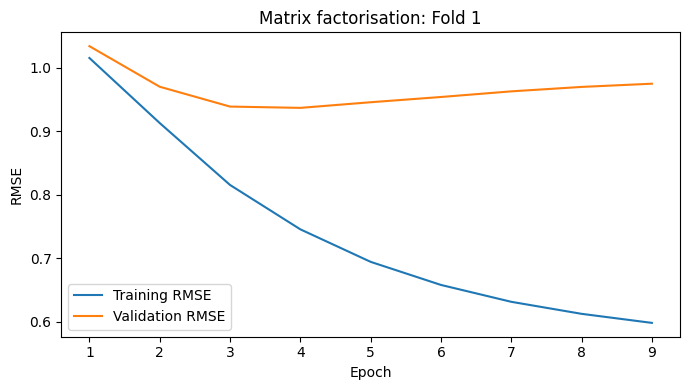

In [ ]:
train_1 = ratings.iloc[folds[0]["train"]]
val_1 = ratings.iloc[folds[0]["val"]]

mf_1 = fit_recommender(
    MatrixFactorisation,
    train_1,
    val_1,
    seed=SEED + 1
)

mf_metrics = rating_metrics(
    val_1["rating"], predict_ratings(mf_1, val_1)
)

comparison = baseline_scores.loc[
    baseline_scores["Fold"] == 1,
    ["Baseline", "RMSE", "MAE"]
].rename(columns={"Baseline": "Model"})

comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "Matrix factorisation",
        **mf_metrics
    }])
], ignore_index=True)

display(comparison.round(4))
print(f"Best epoch: {mf_1['best_epoch']}")
print(f"Training time: {mf_1['training_seconds']:.1f} seconds")

mf_1["history"].plot(
    x="Epoch",
    y=["Training RMSE", "Validation RMSE"],
    figsize=(7, 4),
    ylabel="RMSE",
    title="Matrix factorisation: Fold 1"
)
plt.tight_layout()
plt.show()

In [ ]:
class NeuralRecommender(nn.Module):
    def __init__(self, n_users, n_movies, mean, factors=20):
        super().__init__()
        self.mean = float(mean)
        self.user_factors = nn.Embedding(n_users, factors)
        self.movie_factors = nn.Embedding(n_movies, factors)
        self.user_bias = nn.Embedding(n_users, 1)
        self.movie_bias = nn.Embedding(n_movies, 1)

        self.network = nn.Sequential(
            nn.Linear(factors * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

        nn.init.normal_(self.user_factors.weight, std=0.05)
        nn.init.normal_(self.movie_factors.weight, std=0.05)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, users, movies):
        features = torch.cat([
            self.user_factors(users),
            self.movie_factors(movies)
        ], dim=1)

        interaction = self.network(features).squeeze(-1)

        return (
            self.mean
            + self.user_bias(users).squeeze(-1)
            + self.movie_bias(movies).squeeze(-1)
            + interaction
        )

Epoch  1 | train RMSE 0.9569 | val RMSE 0.9776
Epoch  5 | train RMSE 0.8899 | val RMSE 0.9325
Epoch 10 | train RMSE 0.8683 | val RMSE 0.9357


,Model,RMSE,MAE
0,Global mean,1.1266,0.9460
1,User mean,1.0432,0.8359
2,Matrix factorisation,0.9369,0.7354
3,Neural recommender,0.9323,0.7308


Best epoch: 8
Training time: 5.6 seconds


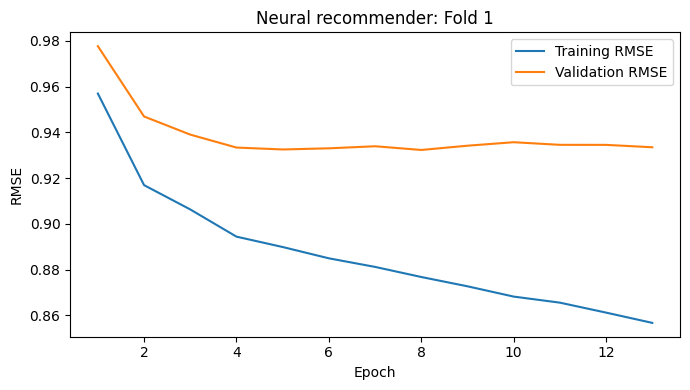

In [ ]:
neural_1 = fit_recommender(
    NeuralRecommender,
    train_1,
    val_1,
    lr=0.003,
    seed=SEED + 1
)

neural_metrics = rating_metrics(
    val_1["rating"], predict_ratings(neural_1, val_1)
)

fold_1_comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "Neural recommender",
        **neural_metrics
    }])
], ignore_index=True)

display(fold_1_comparison.round(4))
print(f"Best epoch: {neural_1['best_epoch']}")
print(f"Training time: {neural_1['training_seconds']:.1f} seconds")

neural_1["history"].plot(
    x="Epoch",
    y=["Training RMSE", "Validation RMSE"],
    figsize=(7, 4),
    ylabel="RMSE",
    title="Neural recommender: Fold 1"
)
plt.tight_layout()
plt.show()

**Initial model comparison**

On Fold 1, matrix factorisation achieved validation RMSE of 0.9369
and MAE of 0.7354, improving on both mean-based baselines.

Validation RMSE reached its minimum at epoch 4, then increased while
training RMSE continued to decrease. This indicates overfitting.
Early stopping restored the checkpoint with the lowest validation RMSE.

The neural model replaces the dot-product interaction with two hidden
layers of 64 and 32 units, using ReLU activations and 20% dropout.
Both models use the same input IDs, training and validation partitions,
prediction clipping, and fallback for unknown users or movies.

These are preliminary results from one fold. A deployment recommendation
requires the full evaluation, including ranking quality, subgroup
performance, and computational cost.

In [ ]:
from contextlib import redirect_stdout
from io import StringIO

settings = [
    {"name": "Original", "factors": 20, "weight_decay": 0.0001},
    {"name": "Stronger L2", "factors": 20, "weight_decay": 0.001},
    {"name": "Fewer factors", "factors": 10, "weight_decay": 0.0001}
]

model_specs = {
    "Matrix factorisation": (MatrixFactorisation, 0.01),
    "Neural recommender": (NeuralRecommender, 0.003)
}

tuning_rows = []
selection_rows = []
selected_models = {}

for fold, split in enumerate(folds, start=1):
    train = ratings.iloc[split["train"]]
    val = ratings.iloc[split["val"]]

    for name, (model_class, lr) in model_specs.items():
        best_rmse = float("inf")
        search_started = perf_counter()

        for setting in settings:
            with redirect_stdout(StringIO()):
                fitted = fit_recommender(
                    model_class,
                    train,
                    val,
                    factors=setting["factors"],
                    lr=lr,
                    weight_decay=setting["weight_decay"],
                    seed=SEED + fold
                )

            metrics = rating_metrics(
                val["rating"], predict_ratings(fitted, val)
            )

            row = {
                "Fold": fold,
                "Model": name,
                "Setting": setting["name"],
                "Factors": setting["factors"],
                "Weight decay": setting["weight_decay"],
                "Learning rate": lr,
                "Best epoch": fitted["best_epoch"],
                "Training seconds": fitted["training_seconds"],
                "Parameters": sum(
                    p.numel() for p in fitted["model"].parameters()
                    if p.requires_grad
                ),
                **metrics
            }
            tuning_rows.append(row)

            if metrics["RMSE"] < best_rmse:
                best_rmse = metrics["RMSE"]
                best_row = row.copy()
                selected_models[(name, fold)] = fitted

        best_row["Search seconds"] = perf_counter() - search_started
        selection_rows.append(best_row)

        print(
            f"Fold {fold} | {name} | "
            f"{best_row['Setting']} | "
            f"validation RMSE {best_rmse:.4f}"
        )

tuning_scores = pd.DataFrame(tuning_rows)
selected_settings = pd.DataFrame(selection_rows)

Fold 1 | Matrix factorisation | Original | validation RMSE 0.9369
Fold 1 | Neural recommender | Stronger L2 | validation RMSE 0.9316
Fold 2 | Matrix factorisation | Fewer factors | validation RMSE 0.9234
Fold 2 | Neural recommender | Stronger L2 | validation RMSE 0.9236
Fold 3 | Matrix factorisation | Fewer factors | validation RMSE 0.9314
Fold 3 | Neural recommender | Original | validation RMSE 0.9287
Fold 4 | Matrix factorisation | Original | validation RMSE 0.9400
Fold 4 | Neural recommender | Stronger L2 | validation RMSE 0.9386
Fold 5 | Matrix factorisation | Original | validation RMSE 0.9360
Fold 5 | Neural recommender | Original | validation RMSE 0.9297


In [ ]:
display(
    selected_settings[[
        "Fold", "Model", "Setting", "Factors",
        "Weight decay", "Best epoch", "RMSE", "MAE",
        "Parameters", "Training seconds", "Search seconds"
    ]].round(4)
)

display(
    selected_settings.groupby("Model")[["RMSE", "MAE"]]
    .agg(["mean", "std"])
    .round(4)
)

,Fold,Model,Setting,Factors,Weight decay,Best epoch,RMSE,MAE,Parameters,Training seconds,Search seconds
0,1,Matrix factorisation,Original,20,0.0001,4,0.9369,0.7354,53571,2.2723,5.0783
1,1,Neural recommender,Stronger L2,20,0.0010,9,0.9316,0.7314,58308,4.3310,19.3493
2,2,Matrix factorisation,Fewer factors,10,0.0001,4,0.9234,0.7282,28072,0.7576,4.8142
3,2,Neural recommender,Stronger L2,20,0.0010,24,0.9236,0.7229,58329,9.9582,18.5642
4,3,Matrix factorisation,Fewer factors,10,0.0001,4,0.9314,0.7337,28248,1.1792,4.6229
5,3,Neural recommender,Original,20,0.0001,15,0.9287,0.7303,58665,6.5590,17.5031
6,4,Matrix factorisation,Original,20,0.0001,4,0.9400,0.7432,53823,0.8010,3.6725
7,4,Neural recommender,Stronger L2,20,0.0010,13,0.9386,0.7378,58560,6.9091,19.1115
8,5,Matrix factorisation,Original,20,0.0001,4,0.9360,0.7403,53844,0.8245,4.4640
9,5,Neural recommender,Original,20,0.0001,8,0.9297,0.7310,58581,4.0145,12.9072


RMSE             MAE        
                        mean     std    mean     std
Model                                               
Matrix factorisation  0.9335  0.0064  0.7361  0.0059
Neural recommender    0.9305  0.0055  0.7307  0.0053

**Hyperparameter selection**

Each model is evaluated under three settings: the original configuration,
stronger L2 regularisation, and fewer latent factors. This is a limited
search designed to examine model capacity and regularisation within a
manageable computational budget.

Within each fold, the setting with the lowest validation RMSE is selected.
Early stopping also uses that fold's validation subset. No test ratings
are used for either decision.

The selected setting may differ between folds. Settings are not chosen
by pooling validation results across folds, because ratings used for
validation in one fold may be test ratings in another.

Selected validation scores describe the tuning process and may be
optimistic. Final performance will be assessed on each fold's held-out
test subset.

In [ ]:
from sklearn.metrics import ndcg_score

def user_ranking_scores(predictions, k=10):
    rows = []

    for user_id, group in predictions.groupby("user_id"):
        relevant = (group["rating"].to_numpy() >= 4).astype(int)

        if len(group) < k or relevant.sum() == 0:
            continue

        score = ndcg_score(
            relevant.reshape(1, -1),
            group["Prediction"].to_numpy().reshape(1, -1),
            k=k,
            ignore_ties=False
        )

        rows.append({
            "user_id": user_id,
            "Candidates": len(group),
            "Relevant movies": int(relevant.sum()),
            "NDCG@10": score
        })

    return pd.DataFrame(
        rows,
        columns=["user_id", "Candidates", "Relevant movies", "NDCG@10"]
    )

In [ ]:
test_rows = []
prediction_frames = []
ranking_frames = []

for fold, split in enumerate(folds, start=1):
    train = ratings.iloc[split["train"]]
    test = ratings.iloc[split["test"]]

    mean = train["rating"].mean()
    user_means = train.groupby("user_id")["rating"].mean()
    movie_means = train.groupby("movie_id")["rating"].mean()

    predictions = {
        "Global mean": np.full(len(test), mean),
        "User mean": (
            test["user_id"].map(user_means).fillna(mean).to_numpy()
        ),
        "Movie mean": (
            test["movie_id"].map(movie_means).fillna(mean).to_numpy()
        )
    }

    for name in model_specs:
        predictions[name] = predict_ratings(
            selected_models[(name, fold)], test
        )

    for name, predicted in predictions.items():
        frame = test.copy()
        frame["Prediction"] = predicted
        frame["Fold"] = fold
        frame["Model"] = name
        prediction_frames.append(frame)

        ranking = user_ranking_scores(frame)
        ranking["Fold"] = fold
        ranking["Model"] = name
        ranking_frames.append(ranking)

        test_rows.append({
            "Fold": fold,
            "Model": name,
            **rating_metrics(test["rating"], predicted),
            "NDCG@10": ranking["NDCG@10"].mean(),
            "Eligible users": len(ranking),
            "Total test users": test["user_id"].nunique()
        })

test_scores = pd.DataFrame(test_rows)
test_predictions = pd.concat(prediction_frames, ignore_index=True)
ranking_scores = pd.concat(ranking_frames, ignore_index=True)

In [ ]:
display(
    test_scores[[
        "Fold", "Model", "RMSE", "MAE", "NDCG@10"
    ]].round(4)
)

display(
    test_scores.groupby("Model")[["RMSE", "MAE", "NDCG@10"]]
    .agg(["mean", "std"])
    .round(4)
)

coverage = test_scores.loc[
    test_scores["Model"] == "Matrix factorisation",
    ["Fold", "Eligible users", "Total test users"]
].copy()

coverage["Eligible users (%)"] = (
    100 * coverage["Eligible users"] / coverage["Total test users"]
)

display(coverage.round(2))

,Fold,Model,RMSE,MAE,NDCG@10
0,1,Global mean,1.1259,0.9444,0.6201
1,1,User mean,1.0402,0.8326,0.6201
2,1,Movie mean,1.0234,0.8152,0.8055
3,1,Matrix factorisation,0.9379,0.7376,0.8138
4,1,Neural recommender,0.9279,0.7284,0.8115
5,2,Global mean,1.1222,0.9440,0.6287
6,2,User mean,1.0429,0.8362,0.6287
7,2,Movie mean,1.0183,0.8129,0.8068
8,2,Matrix factorisation,0.9285,0.7336,0.8224
9,2,Neural recommender,0.9245,0.7260,0.8173


RMSE             MAE         NDCG@10        
                        mean     std    mean     std    mean     std
Model                                                               
Global mean           1.1257  0.0025  0.9448  0.0023  0.6198  0.0063
Matrix factorisation  0.9372  0.0062  0.7391  0.0046  0.8103  0.0104
Movie mean            1.0271  0.0070  0.8190  0.0061  0.7994  0.0063
Neural recommender    0.9332  0.0077  0.7330  0.0071  0.8053  0.0088
User mean             1.0438  0.0050  0.8364  0.0031  0.6198  0.0063

,Fold,Eligible users,Total test users,Eligible users (%)
3,1,583,943,61.82
8,2,581,943,61.61
13,3,579,943,61.40
18,4,584,943,61.93
23,5,584,943,61.93


**Test evaluation**

Selected checkpoints are evaluated on each fold's held-out test ratings.
RMSE and MAE measure rating-prediction error across all test interactions,
including cases handled by the fallback.

NDCG@10 measures ranking quality within each user's held-out rated movies.
Ratings of 4 or 5 are treated as relevant. Users must have at least
10 test ratings and one relevant movie to enter the ranking evaluation.
Scores are averaged equally across eligible users, with ties handled
by scikit-learn.

This protocol avoids labelling unrated movies as disliked. However, it
evaluates a restricted candidate set and favours more-active users.
It cannot establish full-catalogue recommendation quality. Ranking
coverage is reported alongside performance.

Global-mean, user-mean, and movie-mean predictions provide reference
baselines. No model settings are changed in response to test results.

In [ ]:
diagnostic_frames = []
threshold_rows = []

for fold, split in enumerate(folds, start=1):
    train = ratings.iloc[split["train"]]

    user_counts = train.groupby("user_id").size()
    movie_counts = train.groupby("movie_id").size()

    user_low, user_high = user_counts.quantile([0.25, 0.75])
    movie_low, movie_high = movie_counts.quantile([0.25, 0.75])

    threshold_rows.append({
        "Fold": fold,
        "User count: 25th percentile": user_low,
        "User count: 75th percentile": user_high,
        "Movie count: 25th percentile": movie_low,
        "Movie count: 75th percentile": movie_high
    })

    frame = test_predictions.loc[
        (test_predictions["Fold"] == fold)
        & test_predictions["Model"].isin(model_specs)
    ].copy()

    frame["User training ratings"] = (
        frame["user_id"].map(user_counts).fillna(0)
    )
    frame["Movie training ratings"] = (
        frame["movie_id"].map(movie_counts).fillna(0)
    )

    frame["User activity"] = np.select(
        [
            frame["User training ratings"] <= user_low,
            frame["User training ratings"] <= user_high
        ],
        ["Low", "Medium"],
        default="High"
    )

    frame["Movie popularity"] = np.select(
        [
            frame["Movie training ratings"] == 0,
            frame["Movie training ratings"] <= movie_low,
            frame["Movie training ratings"] <= movie_high
        ],
        ["Unseen", "Low", "Medium"],
        default="High"
    )

    frame["Error"] = frame["Prediction"] - frame["rating"]
    frame["Absolute error"] = frame["Error"].abs()
    diagnostic_frames.append(frame)

diagnostic_predictions = pd.concat(
    diagnostic_frames, ignore_index=True
)

display(pd.DataFrame(threshold_rows).round(2))

,Fold,User count: 25th percentile,User count: 75th percentile,Movie count: 25th percentile,Movie count: 75th percentile
0,1,21.0,94.0,5.0,53.0
1,2,21.0,94.5,5.0,54.0
2,3,21.0,94.5,5.0,52.0
3,4,22.0,94.0,5.0,53.0
4,5,21.0,94.0,5.0,53.0


In [ ]:
subgroup_rows = []

for axis in ["User activity", "Movie popularity"]:
    for (model, group), frame in diagnostic_predictions.groupby(
        ["Model", axis]
    ):
        user_mae = frame.groupby("user_id")["Absolute error"].mean()

        subgroup_rows.append({
            "Analysis": axis,
            "Model": model,
            "Group": group,
            "Test ratings": len(frame),
            "Users": frame["user_id"].nunique(),
            "Movies": frame["movie_id"].nunique(),
            **rating_metrics(frame["rating"], frame["Prediction"]),
            "User-macro MAE": user_mae.mean(),
            "Mean error": frame["Error"].mean()
        })

subgroup_scores = pd.DataFrame(subgroup_rows)

for axis in ["User activity", "Movie popularity"]:
    print(axis)
    display(
        subgroup_scores.loc[
            subgroup_scores["Analysis"] == axis
        ].drop(columns="Analysis").round(4)
    )

User activity


,Model,Group,Test ratings,Users,Movies,RMSE,MAE,User-macro MAE,Mean error
0,Matrix factorisation,High,58841,237,1653,0.9198,0.7237,0.7204,0.0362
1,Matrix factorisation,Low,6237,267,776,1.0045,0.8063,0.8090,0.0024
2,Matrix factorisation,Medium,34922,479,1408,0.9539,0.7531,0.7569,0.0239
3,Neural recommender,High,58841,237,1653,0.9130,0.7167,0.7162,0.0213
4,Neural recommender,Low,6237,267,776,1.0121,0.8006,0.8045,0.0029
5,Neural recommender,Medium,34922,479,1408,0.9522,0.7483,0.7510,0.0105


Movie popularity


,Model,Group,Test ratings,Users,Movies,RMSE,MAE,User-macro MAE,Mean error
6,Matrix factorisation,High,70081,943,434,0.9143,0.7178,0.7469,-0.0032
7,Matrix factorisation,Low,1928,448,431,1.1555,0.9530,0.9076,0.3769
8,Matrix factorisation,Medium,27755,936,856,0.9752,0.7770,0.8119,0.0852
9,Matrix factorisation,Unseen,236,102,197,1.1176,0.8787,0.9944,0.4721
10,Neural recommender,High,70081,943,434,0.9180,0.7192,0.7469,0.0046
11,Neural recommender,Low,1928,448,431,1.0650,0.8541,0.8953,0.1219
12,Neural recommender,Medium,27755,936,856,0.9596,0.7580,0.7906,0.0347
13,Neural recommender,Unseen,236,102,197,1.1176,0.8787,0.9944,0.4721


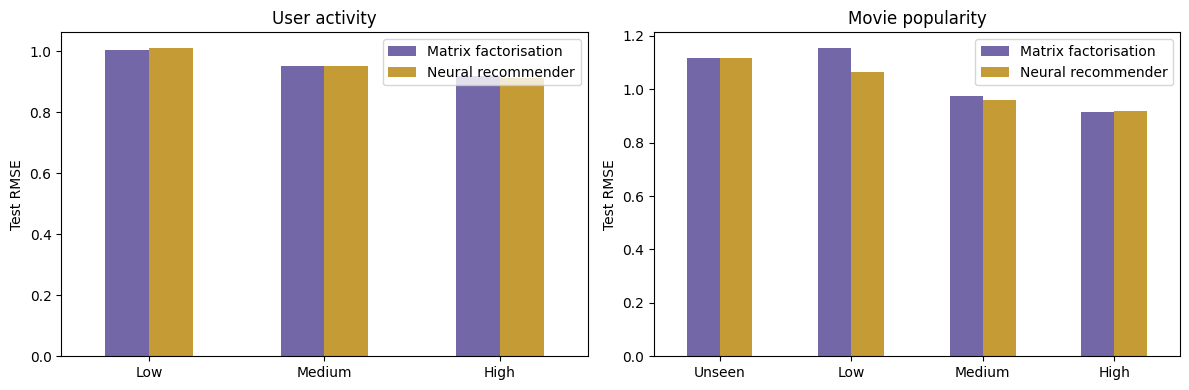

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

group_orders = {
    "User activity": ["Low", "Medium", "High"],
    "Movie popularity": ["Unseen", "Low", "Medium", "High"]
}

for ax, (analysis, order) in zip(axes, group_orders.items()):
    chart = (
        subgroup_scores.loc[subgroup_scores["Analysis"] == analysis]
        .pivot(index="Group", columns="Model", values="RMSE")
        .reindex(order)
    )

    chart.plot.bar(
        ax=ax,
        color=["#7367A8", "#C49B35"],
        rot=0
    )
    ax.set(title=analysis, xlabel="", ylabel="Test RMSE")
    ax.legend(title="")

fig.tight_layout()
plt.show()

**Subgroup diagnostic analysis**

User activity and movie popularity groups are defined separately within
each fold using training rating counts. Low groups contain entities at
or below the 25th percentile; High groups contain entities above the
75th percentile. Remaining entities form the Medium group. Movies absent
from training form a separate Unseen group.

Held-out predictions are pooled across folds. Each test interaction
appears once per model, but an entity's group can change between folds.
Groups therefore describe the amount of training evidence available
for each prediction, rather than permanent user or movie categories.

RMSE and MAE describe interaction-level errors. User-macro MAE gives
equal weight to users represented within each group. Mean signed error
indicates average overprediction or underprediction.

Performance differences identify potential disparities, rather than
proving discrimination or establishing their causes. Group sample
sizes must be considered, particularly for unseen and rarely rated movies.

In [ ]:
mf_explain = selected_models[("Matrix factorisation", 1)]
neural_explain = selected_models[("Neural recommender", 1)]

train_1 = ratings.iloc[folds[0]["train"]]
test_1 = ratings.iloc[folds[0]["test"]]

known = (
    test_1["user_id"].isin(mf_explain["users"])
    & test_1["movie_id"].isin(mf_explain["movies"])
)

examples = (
    test_1.loc[known]
    .sample(n=3, random_state=SEED)
    .reset_index(drop=True)
)

background = (
    train_1[["user_id", "movie_id"]]
    .sample(n=100, random_state=SEED)
    .to_numpy()
)

display(examples[["user_id", "movie_id", "rating"]])

,user_id,movie_id,rating
0,608,190,4
1,897,239,2
2,141,1280,1


In [ ]:
model = mf_explain["model"]
model_device = next(model.parameters()).device

users = torch.as_tensor(
    mf_explain["users"].get_indexer(examples["user_id"]),
    dtype=torch.long,
    device=model_device
)
movies = torch.as_tensor(
    mf_explain["movies"].get_indexer(examples["movie_id"]),
    dtype=torch.long,
    device=model_device
)

model.eval()
with torch.no_grad():
    user_bias = model.user_bias(users).squeeze(-1).cpu().numpy()
    movie_bias = model.movie_bias(movies).squeeze(-1).cpu().numpy()
    interaction = (
        model.user_factors(users) * model.movie_factors(movies)
    ).sum(dim=1).cpu().numpy()

mf_components = examples[["user_id", "movie_id", "rating"]].copy()
mf_components["Training mean"] = model.mean
mf_components["User bias"] = user_bias
mf_components["Movie bias"] = movie_bias
mf_components["Interaction"] = interaction

component_columns = [
    "Training mean", "User bias", "Movie bias", "Interaction"
]

mf_components["Raw prediction"] = (
    mf_components[component_columns].sum(axis=1)
)
mf_components["Prediction"] = (
    mf_components["Raw prediction"].clip(1, 5)
)

assert np.allclose(
    mf_components["Prediction"],
    predict_ratings(mf_explain, examples),
    atol=1e-5
)

display(mf_components.round(4))

,user_id,movie_id,rating,Training mean,User bias,Movie bias,Interaction,Raw prediction,Prediction
0,608,190,4,3.5325,0.0434,0.4396,0.1591,4.1747,4.1747
1,897,239,2,3.5325,0.2754,0.0086,-0.0932,3.7233,3.7233
2,141,1280,1,3.5325,-0.1502,-0.0644,-0.0633,3.2547,3.2547


In [ ]:
import shap

example_pairs = examples[["user_id", "movie_id"]].to_numpy()

explanation_models = {
    "Matrix factorisation": mf_explain,
    "Neural recommender": neural_explain
}

shap_results = {}
shap_rows = []

for name, fitted in explanation_models.items():
    def predict_pairs(pairs, fitted=fitted):
        frame = pd.DataFrame(
            np.asarray(pairs, dtype=np.int64),
            columns=["user_id", "movie_id"]
        )
        return predict_ratings(fitted, frame)

    explainer = shap.KernelExplainer(
        predict_pairs,
        background,
        feature_names=["User identity", "Movie identity"]
    )

    values = np.asarray(
        explainer.shap_values(
            example_pairs,
            nsamples=4,
            l1_reg=0,
            silent=True
        )
    )
    base = float(np.asarray(explainer.expected_value).item())
    predicted = predict_pairs(example_pairs)
    reconstructed = base + values.sum(axis=1)

    assert np.allclose(reconstructed, predicted, atol=1e-5)

    shap_results[name] = {"values": values, "base": base}

    for i, example in examples.iterrows():
        shap_rows.append({
            "Model": name,
            "user_id": int(example["user_id"]),
            "movie_id": int(example["movie_id"]),
            "Actual rating": int(example["rating"]),
            "SHAP baseline": base,
            "User contribution": values[i, 0],
            "Movie contribution": values[i, 1],
            "Prediction": predicted[i],
            "Reconstruction error": abs(
                reconstructed[i] - predicted[i]
            )
        })

shap_comparison = pd.DataFrame(shap_rows)
display(shap_comparison.round(4))

,Model,user_id,movie_id,Actual rating,SHAP baseline,User contribution,Movie contribution,Prediction,Reconstruction error
0,Matrix factorisation,608,190,4,3.6093,0.0187,0.5467,4.1747,0.0
1,Matrix factorisation,897,239,2,3.6093,0.2911,-0.1771,3.7233,0.0
2,Matrix factorisation,141,1280,1,3.6093,-0.1660,-0.1886,3.2547,0.0
3,Neural recommender,608,190,4,3.5885,-0.1024,0.6517,4.1378,0.0
4,Neural recommender,897,239,2,3.5885,0.4298,-0.0207,3.9976,0.0
5,Neural recommender,141,1280,1,3.5885,0.2169,-0.2595,3.5459,0.0


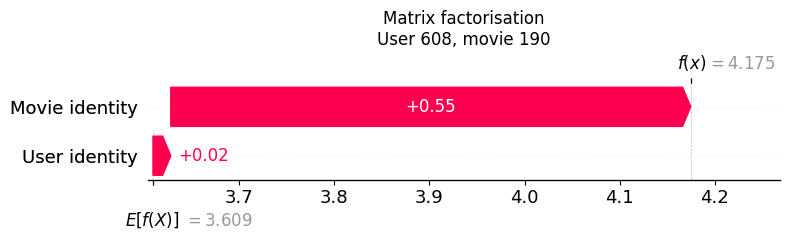

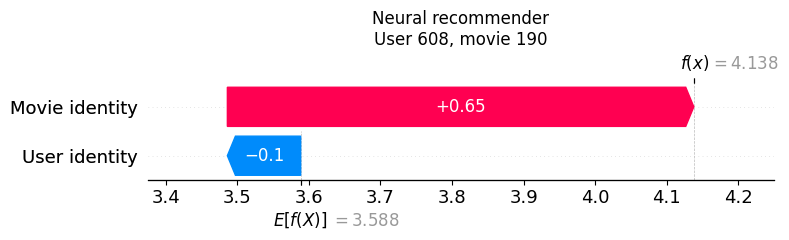

In [ ]:
example = examples.iloc[0]

for name, result in shap_results.items():
    explanation = shap.Explanation(
        values=result["values"][0],
        base_values=result["base"],
        feature_names=["User identity", "Movie identity"]
    )

    shap.plots.waterfall(explanation, max_display=2, show=False)
    plt.title(
        f"{name}\n"
        f"User {int(example['user_id'])}, "
        f"movie {int(example['movie_id'])}"
    )
    plt.tight_layout()
    plt.show()

**Explainability approach**

Matrix factorisation is decomposed exactly into its training mean,
user bias, movie bias, and latent-factor interaction. The sum gives
the raw prediction; clipping gives the evaluated prediction.

Kernel SHAP is applied to both models using the same three randomly
selected test interactions and 100 training interactions as background.
The two inputs are categorical user and movie identities. Masking
substitutes observed IDs rather than treating IDs as continuous quantities.

SHAP contributions describe changes relative to each model's background
prediction. They allocate interaction effects between the two inputs,
so they are not equivalent to the matrix-factorisation bias terms.

These explanations do not identify genre preferences, explain individual
historical ratings, or establish causal effects. Background substitutions
may also produce user–movie pairs not observed during training.
Reconstruction checks verify numerical consistency, not the validity
of these assumptions.

The examples illustrate local behaviour and are not a global
explainability assessment. Model parameters remain unchanged.

**Explainability findings**

For user 608 and movie 190, both models predict close to the actual
rating of 4: matrix factorisation predicts 4.1747 and the neural model
predicts 4.1378.

The matrix-factorisation decomposition shows a positive movie bias
of 0.4396 and interaction contribution of 0.1591. Its user bias is
smaller, at 0.0434.

SHAP assigns positive movie contributions in both models. However,
the user contribution is slightly positive for matrix factorisation
and negative for the neural model. Similar outputs therefore do not
imply identical attribution patterns.

Both models overpredict the other two example ratings. Numerical
reconstruction confirms that explanations match the model outputs;
it does not establish prediction accuracy or causal validity.
These three examples illustrate local behaviour only.

In [ ]:
with ZipFile(BytesIO(archive_bytes)) as archive:
    with archive.open("ml-100k/u.item") as movie_file:
        movie_titles = pd.read_csv(
            movie_file,
            sep="|",
            encoding="latin-1",
            header=None,
            usecols=[0, 1]
        )

movie_titles.columns = ["movie_id", "Title"]
display(movie_titles.head())

,movie_id,Title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [ ]:
def show_recommendations(user_id, n=10):
    mf = selected_models[("Matrix factorisation", 1)]

    if user_id not in mf["users"]:
        raise ValueError("Choose a user present in Fold 1 training data")

    history = train_1.loc[train_1["user_id"] == user_id]
    seen_movies = set(history["movie_id"])

    candidates = pd.DataFrame({
        "movie_id": [
            movie_id for movie_id in mf["movies"]
            if movie_id not in seen_movies
        ]
    })
    candidates["user_id"] = user_id

    print(f"User {user_id}: highly rated training movies")
    display(
        history.loc[history["rating"] >= 4]
        .merge(movie_titles, on="movie_id")
        .sort_values(
            ["rating", "movie_id"], ascending=[False, True]
        )[["Title", "rating"]]
        .head(n)
    )

    recommendations = []

    for name in model_specs:
        scored = candidates.copy()
        scored["Prediction"] = predict_ratings(
            selected_models[(name, 1)], scored
        )

        top = (
            scored.sort_values(
                ["Prediction", "movie_id"],
                ascending=[False, True]
            )
            .head(n)
            .merge(movie_titles, on="movie_id")
            .reset_index(drop=True)
        )

        top.insert(0, "Rank", np.arange(1, len(top) + 1))
        top["Model"] = name
        recommendations.append(
            top[["Model", "Rank", "Title", "Prediction"]]
        )

    recommendations = pd.concat(recommendations, ignore_index=True)

    for name in model_specs:
        print(name)
        display(
            recommendations.loc[
                recommendations["Model"] == name,
                ["Rank", "Title", "Prediction"]
            ].round(3)
        )

    return recommendations

In [ ]:
demo_recommendations = show_recommendations(user_id=608)

User 608: highly rated training movies


,Title,rating
64,Seven (Se7en) (1995),5
63,Taxi Driver (1976),5
4,Clerks (1994),5
56,Pulp Fiction (1994),5
61,Three Colors: Red (1994),5
45,What's Eating Gilbert Grape (1993),5
18,Much Ado About Nothing (1993),5
8,"Remains of the Day, The (1993)",5
44,"Silence of the Lambs, The (1991)",5
55,"Godfather, The (1972)",5


Matrix factorisation


,Rank,Title,Prediction
0,1,Trainspotting (1996),4.617
1,2,Brazil (1985),4.423
2,3,Mighty Aphrodite (1995),4.401
3,4,Rosencrantz and Guildenstern Are Dead (1990),4.388
4,5,"Apartment, The (1960)",4.374
5,6,"Clockwork Orange, A (1971)",4.334
6,7,Hoop Dreams (1994),4.245
7,8,Heathers (1989),4.237
8,9,Richard III (1995),4.225
9,10,Three Colors: Blue (1993),4.222


Neural recommender


,Rank,Title,Prediction
10,1,Schindler's List (1993),4.325
11,2,"Close Shave, A (1995)",4.289
12,3,"Wrong Trousers, The (1993)",4.263
13,4,Lawrence of Arabia (1962),4.190
14,5,"Usual Suspects, The (1995)",4.178
15,6,One Flew Over the Cuckoo's Nest (1975),4.171
16,7,Wallace & Gromit: The Best of Aardman Animatio...,4.167
17,8,Henry V (1989),4.138
18,9,To Kill a Mockingbird (1962),4.138
19,10,Good Will Hunting (1997),4.137


**Recommendation demonstration**

The demonstration uses the selected Fold 1 models and displays their
highest-scoring candidate movies for an existing user. Candidates exclude
movies rated by that user in the Fold 1 training subset and include only
movies represented in that training subset.

Predicted ratings are estimates, not probabilities or verified preferences.
Some candidates have ratings in the validation or test subsets, but
those ratings are not supplied to the recommendation function.

This demonstration ranks a broader candidate set than the reported
NDCG evaluation. Its output illustrates inference behaviour; it is not
additional evidence of full-catalogue recommendation quality.

**Ethical considerations**

**Data provenance and privacy**

MovieLens 100K was collected by GroupLens at the University of Minnesota
during 1997–1998. Its demographic file includes age, gender, occupation,
and ZIP code. This project does not load those demographic fields.

The modelling data contain numeric user IDs, ratings, and timestamps,
rather than names. These should still be treated as potentially linkable
behavioural records, not assumed to be risk-free because names are absent.

The dataset documentation permits research use subject to conditions.
It requires permission for redistribution and commercial use.
Research access does not establish consent for a new commercial service.
A deployed system should collect only necessary data, explain its use,
restrict access, and provide appropriate retention and deletion controls.

**Representation and performance disparities**

The dataset excludes users with fewer than 20 ratings or incomplete
demographic information. It therefore provides limited evidence about
new users, and its age limits relevance to current audiences.

Both models have higher RMSE for low-activity users. Low-popularity
movies also have higher errors than high-popularity movies.
The neural model improves low-popularity movie RMSE from 1.1555 to
1.0650, but slightly worsens low-activity user RMSE.

These findings show uneven predictive performance, not proof of
demographic discrimination. Protected-group fairness was not evaluated.
The ranking evaluation also excludes approximately 38% of users,
so its results cannot represent every user equally.

**Errors and potential harm**

If predicted ratings of at least 4 are treated as positive recommendations,
a false positive promotes a movie the user rates below 4. This may waste
time and reduce trust. A false negative overlooks a movie the user would
rate at least 4, restricting discovery.

Repeatedly prioritising well-represented movies could reduce exposure
for less-popular titles and reinforce existing consumption patterns.
Our error analysis does not directly measure this exposure effect.

Potential safeguards include user feedback controls, exploration of
less-exposed titles, subgroup monitoring, and separate evaluation of
new-user and new-movie strategies. These safeguards are proposals,
not implemented or validated interventions.

**Deployment considerations**

**Recommended starting model**

For an initial recommendation pilot, I would select matrix factorisation. It achieves slightly higher mean NDCG@10 than the neural model (0.8103 versus 0.8053), has an exact prediction decomposition, and required less training time in these experiments.

This is a conditional engineering recommendation, not evidence that matrix factorisation is universally superior. The neural model has slightly better overall rating accuracy and lower errors for low-popularity movies. The small aggregate differences have not been shown to be statistically significant.

**Serving and scalability**

The selected architecture could be retrained on an authorised, current dataset using a separate validation process. Model weights, ID mappings, fallback statistics, and software versions would be packaged together.

An authenticated application API could call a hosted inference endpoint, such as Amazon SageMaker AI, to score candidate movies. The application would exclude consumed or unavailable movies before returning results.

Matrix factorisation permits efficient candidate scoring through matrix operations. Precomputed recommendation lists and caching could reduce repeated computation. Actual latency, throughput, memory use, and hosting cost require benchmarking; training times do not establish inference speed.

**Cold start, monitoring, and retraining**

The current mean-based fallback cannot provide meaningful personalised rankings for unknown users or movies. A production pilot would need a separately evaluated approach, such as onboarding preferences or content-based recommendations.

Monitoring should cover response latency, failures, fallback frequency, catalogue coverage, recommendation exposure, and subgroup performance. Rating-error monitoring requires subsequently observed ratings; clicks should not automatically be treated as equivalent feedback.

Retraining should respond to sufficient new data or sustained performance deterioration. Updated models should undergo chronological validation, subgroup checks, and controlled release with rollback.

**Conclusion and limitations**

The neural recommender achieved slightly lower mean test RMSE
(0.9332 versus 0.9372) and MAE (0.7330 versus 0.7391).
Matrix factorisation achieved slightly higher mean NDCG@10
(0.8103 versus 0.8053).

Neither model was best across all measures or subgroups. Both struggled
with limited training evidence, while the neural model reduced errors
for low-popularity movies. Shared fallback predictions explain their
identical unseen-movie results.

Matrix factorisation provides an exact computational decomposition.
SHAP explains both models at the identity level, but does not establish
semantic preferences, causal effects, or prediction correctness.

The study uses random splits of a historical dataset, a limited
hyperparameter search, and one training seed per fold. Ranking is
restricted to held-out rated movies and eligible users. Confidence
intervals, demographic fairness, full-catalogue ranking, new-user
generalisation, and production inference performance were not assessed.

The evidence supports matrix factorisation as a practical starting
point for a recommendation pilot, subject to current-data validation
and operational testing.

In [ ]:
import sys
from importlib.metadata import version
from hashlib import sha256

packages = [
    "numpy", "pandas", "matplotlib",
    "scikit-learn", "torch", "shap"
]

display(pd.DataFrame({
    "Package": packages,
    "Version": [version(package) for package in packages]
}))

print(f"Python: {sys.version.split()[0]}")
print(f"Device: {device}")
print(f"Base seed: {SEED}")
print(f"Dataset archive SHA-256: {sha256(archive_bytes).hexdigest()}")

display(
    selected_settings.groupby("Model")[[
        "Parameters", "Training seconds", "Search seconds"
    ]].mean().round(3)
)

,Package,Version
0,numpy,2.1.3
1,pandas,2.2.3
2,matplotlib,3.10.0
3,scikit-learn,1.6.1
4,torch,2.11.0+cpu
5,shap,0.52.0


Python: 3.13.16
Device: cpu
Base seed: 42
Dataset archive SHA-256: 50d2a982c66986937beb9ffb3aa76efe955bf3d5c6b761f4e3a7cd717c6a3229


,Parameters,Training seconds,Search seconds
Model,,,
Matrix factorisation,43511.6,1.167,4.530
Neural recommender,58488.6,6.354,17.487


**References**

Harper, F. M. and Konstan, J. A. (2015).
The MovieLens Datasets: History and Context.
ACM Transactions on Interactive Intelligent Systems, 5(4), Article 19.
https://doi.org/10.1145/2827872

GroupLens. MovieLens 100K dataset documentation and usage conditions.
https://files.grouplens.org/datasets/movielens/ml-100k/README

He, X., Liao, L., Zhang, H., Nie, L., Hu, X. and Chua, T.-S. (2017).
Neural Collaborative Filtering.
Proceedings of the 26th International Conference on World Wide Web.
https://doi.org/10.1145/3038912.3052569

SHAP. KernelExplainer documentation.
https://shap.readthedocs.io/en/stable/generated/shap.KernelExplainer.html

Scikit-learn. NDCG documentation.
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ndcg_score.html

PyTorch. Saving and loading models.
https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html

AWS. Amazon SageMaker AI real-time inference.
https://docs.aws.amazon.com/sagemaker/latest/dg/realtime-endpoints.html
